# Time Series

### Dataset: Apple Stock

### Ejercicio 1: Import
Import pandas, numpy, matplotlib

In [1]:
# Pista: import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
assert 'pd' in dir()
print('✓ OK')


✓ OK


### Ejercicio 2: Load stock
https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/09_Time_Series/Apple_Stock/appl_1980_2014.csv

In [3]:
# Pista: pd.read_csv()
apple = pd.read_csv('https://raw.githubusercontent.com/guipsamora/pandas_exercises/master/09_Time_Series/Apple_Stock/appl_1980_2014.csv')
apple.head()


,Date,Open,High,Low,Close,Volume,Adj Close
0,2014-07-08,96.27,96.80,93.92,95.35,65130000,95.35
1,2014-07-07,94.14,95.99,94.10,95.97,56305400,95.97
2,2014-07-03,93.67,94.10,93.20,94.03,22891800,94.03
3,2014-07-02,93.87,94.06,93.09,93.48,28420900,93.48
4,2014-07-01,93.52,94.07,93.13,93.52,38170200,93.52


In [4]:
assert apple.shape[0] > 0
print('✓ Cargado')


✓ Cargado


### Ejercicio 3: Check types
Check column types

In [5]:
# Pista: .dtypes
apple.dtypes


Date             str
Open         float64
High         float64
Low          float64
Close        float64
Volume         int64
Adj Close    float64
dtype: object

In [6]:
print('OK')
print('✓ OK')


OK
✓ OK


### Ejercicio 4: To datetime
Convert Date to datetime

In [7]:
# Pista: pd.to_datetime(apple['Date'])
apple_dt = apple.copy()
apple_dt['Date'] = pd.to_datetime(apple_dt['Date'])
print(apple_dt['Date'].dtype)


datetime64[us]


In [8]:
assert apple_dt is not None
print('✓ OK')


✓ OK


### Ejercicio 5: Set index
Set Date as index

In [9]:
# Pista: .set_index('Date')
apple_idx = apple_dt.set_index('Date')
apple_idx.head()


,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
2014-07-08,96.27,96.80,93.92,95.35,65130000,95.35
2014-07-07,94.14,95.99,94.10,95.97,56305400,95.97
2014-07-03,93.67,94.10,93.20,94.03,22891800,94.03
2014-07-02,93.87,94.06,93.09,93.48,28420900,93.48
2014-07-01,93.52,94.07,93.13,93.52,38170200,93.52


In [10]:
assert apple_idx.index.name == 'Date'
print('✓ OK')


✓ OK


### Ejercicio 6: Sort index
Sort by date ascending

In [11]:
# Pista: .sort_index()
apple_sorted = apple_idx.sort_index()
apple_sorted.head()


,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
1980-12-12,28.75,28.87,28.75,28.75,117258400,0.45
1980-12-15,27.38,27.38,27.25,27.25,43971200,0.42
1980-12-16,25.37,25.37,25.25,25.25,26432000,0.39
1980-12-17,25.87,26.00,25.87,25.87,21610400,0.40
1980-12-18,26.63,26.75,26.63,26.63,18362400,0.41


In [12]:
assert apple_sorted is not None
print('✓ OK')


✓ OK


### Ejercicio 7: Check dups
Check duplicate dates

In [13]:
# Pista: .duplicated().any()
has_dup = apple_sorted.index.duplicated().any()
print('Fechas duplicadas:', has_dup)


Fechas duplicadas: False


In [14]:
assert isinstance(has_dup, (bool, np.bool_))
print('✓ OK')


✓ OK


### Ejercicio 8: Resample month
Last business day of month

In [15]:
# Pista: .resample('BM').last()
# pandas >= 2.2 renombró los alias 'M' -> 'ME' y 'BM' -> 'BME'
_new = tuple(int(x) for x in pd.__version__.split('.')[:2]) >= (2, 2)
MONTH_END = 'ME' if _new else 'M'
BUS_MONTH_END = 'BME' if _new else 'BM'
monthly = apple_sorted.resample(BUS_MONTH_END).last()
monthly.head()


,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
1980-12-31,34.25,34.25,34.13,34.13,8937600,0.53
1981-01-30,28.50,28.50,28.25,28.25,11547200,0.44
1981-02-27,26.50,26.75,26.50,26.50,3690400,0.41
1981-03-31,24.75,24.75,24.50,24.50,3998400,0.38
1981-04-30,28.38,28.62,28.38,28.38,3152800,0.44


In [16]:
assert monthly is not None
print('✓ OK')


✓ OK


### Ejercicio 9: Date diff
Days between first and last

In [17]:
# Pista: (apple_idx.index[-1] - apple_idx.index[0]).days
days_diff = (apple_sorted.index[-1] - apple_sorted.index[0]).days
print(days_diff)


12261


In [18]:
assert isinstance(days_diff, (int, np.integer))
print('✓ OK')


✓ OK


### Ejercicio 10: Months count
Number of months

In [19]:
# Pista: len(apple_idx.resample('M'))
months = len(apple_sorted.resample(MONTH_END))
print(months)


404


In [20]:
assert months > 0
print('✓ OK')


✓ OK


### Ejercicio 11: Plot close
Plot closing price

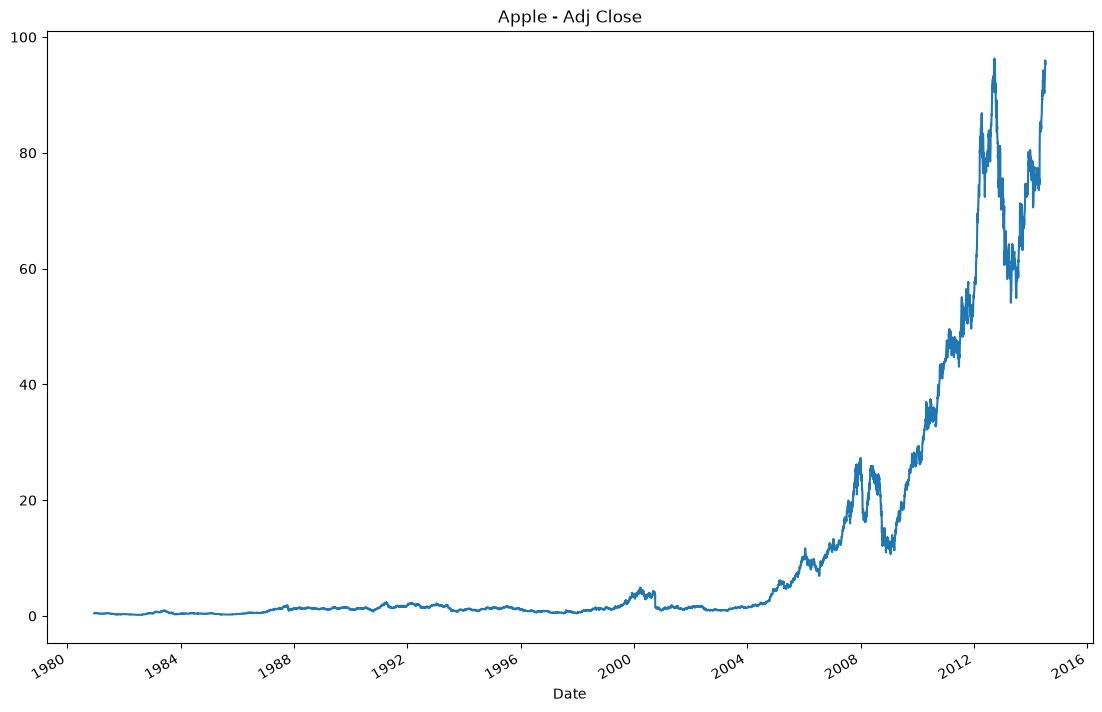

In [21]:
# Pista: apple_idx['Adj Close'].plot(figsize=(13.5, 9))
plot_close = apple_sorted['Adj Close'].plot(figsize=(13.5, 9), title='Apple - Adj Close')
plt.show()


In [22]:
assert plot_close is not None
print('✓ OK')


✓ OK


### Ejercicio 12: Rolling mean
30-day rolling mean

In [23]:
# Pista: .rolling(window=30).mean()
rolling = apple_sorted['Adj Close'].rolling(window=30).mean()
rolling.tail()


Date
2014-07-01    91.011000
2014-07-02    91.247333
2014-07-03    91.494333
2014-07-07    91.801667
2014-07-08    92.055667
Name: Adj Close, dtype: float64

In [24]:
assert rolling is not None
print('✓ OK')


✓ OK


### Ejercicio 13: Year group
Group by year

In [25]:
# Pista: .groupby(apple_idx.index.year).mean()
yearly = apple_sorted.groupby(apple_sorted.index.year).mean()
yearly.tail()


,Open,High,Low,Close,Volume,Adj Close
Date,,,,,,
2010,259.957619,262.368810,256.847619,259.842460,1.498263e+08,35.479802
2011,364.061429,367.423571,360.297698,364.004325,1.230747e+08,49.703135
2012,576.652720,581.825400,569.921160,576.049720,1.319642e+08,78.847600
2013,473.128135,477.638929,468.247103,472.634881,1.016087e+08,65.994563
2014,477.553256,481.363721,474.229922,478.036589,7.265242e+07,80.837674


In [26]:
assert yearly is not None
print('✓ OK')


✓ OK


### Ejercicio 14: Volatility
Daily returns

In [27]:
# Pista: .pct_change()
returns = apple_sorted['Adj Close'].pct_change()
returns.tail()


Date
2014-07-01    0.006349
2014-07-02   -0.000428
2014-07-03    0.005884
2014-07-07    0.020632
2014-07-08   -0.006460
Name: Adj Close, dtype: float64

In [28]:
assert returns is not None
print('✓ OK')


✓ OK


### Ejercicio 15: Cumulative
Cumulative returns

In [29]:
# Pista: (1 + .pct_change()).cumprod() - 1
cum_ret = (1 + apple_sorted['Adj Close'].pct_change()).cumprod() - 1
print(cum_ret.iloc[-1])


210.88888888888917


In [30]:
assert cum_ret is not None
print('✓ OK')


✓ OK


## ¡Completado! 🎉